# Historical E-commerce Sales Analysis and Forecasting

## Business Context:

The client company is Eyard Ltd selling products through online channels especially eBay. They have dataset of previous sales that contains:
- Order ID
- Purchase Date
- Product ID
- Customer ID
- Quantity
- Discount
- Payment Method
- Payment Status
- Product Name
- Product Category
- Unit Price

They want to use this data to analyse business progress like:
- What is growth rate?
- What months of the year are weakest?
- What months of the year are strongest?
- What are products are most selling?
- Whether sales are improving?
- What would be future sales look like?

They need data science consultant to analyse this data because this raw data is not very useful for management to make future decisions.

## Data Exploration:

The dataset provided consists of 2 separate files, one for orders and one for products.

### Loading Orders dataset and checking shape of the dataset

In [5]:
import pandas as pd

data1 = pd.read_csv(r'D:\Docs\MSc Data Science, AI and Digital Business\M504 - AI and Applications\Dataset\orders.csv')
data1.shape

(50120, 8)

The orders dataset contains 50120 rows and 8 columns.

### Checking first and last records of dataset

In [476]:
data1.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status
0,500001,103695,2025-08-28,2003,4.0,0.1,Gateway,Completed
1,500002,107935,2024-05-31,2014,1.0,0.1,Wallet,Completed
2,500003,105141,2025-08-10,2002,1.0,0.2,CardToCard,Completed
3,500004,108780,2024-10-11,2012,1.0,0.1,Gateway,Completed
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed


In [478]:
data1.tail()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status
50115,546916,106069,2024-11-08,2003,1.0,0.10,CardToCard,Completed
50116,509802,107180,2024-09-19,2012,1.0,0.10,CardToCard,Completed
50117,538801,109723,2025-02-19,2006,2.0,0.05,Wallet,Completed
50118,524670,108719,2025-08-08,2013,1.0,0.05,Gateway,Completed
50119,544234,106789,2024-04-03,2003,1.0,0.00,Gateway,Completed


head() helps in understanding the beginning of the dataset and tail() helps in understanding whether there are any unusual entries like summary etc.

### Checking the datatypes in dataset

In [482]:
data1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50120 entries, 0 to 50119
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   OrderID        50120 non-null  int64  
 1   CustomerID     50120 non-null  int64  
 2   OrderDate      50085 non-null  object 
 3   ProductID      50120 non-null  int64  
 4   Quantity       50040 non-null  float64
 5   Discount       49899 non-null  float64
 6   PaymentMethod  49668 non-null  object 
 7   Status         50120 non-null  object 
dtypes: float64(2), int64(3), object(3)
memory usage: 3.1+ MB


The information reveals that OrderDate has datatype of object and it can be changed to datetime datatype for future use.

### Checking the null values in the orders dataset

In [486]:
data1.isnull().sum()

OrderID            0
CustomerID         0
OrderDate         35
ProductID          0
Quantity          80
Discount         221
PaymentMethod    452
Status             0
dtype: int64

This information is useful in deciding whether to drop the missing value rows
or we can fill these with appropriate values.

### Checking Duplicate values in orders dataset

In [490]:
data1.duplicated().sum()

120

In [492]:
data1.describe()

,OrderID,CustomerID,ProductID,Quantity,Discount
count,50120.000000,50120.000000,50120.000000,50040.000000,49899.000000
mean,525003.244872,105543.821788,2009.458799,1.881455,0.075130
std,14433.904231,22079.891005,5.577743,1.078846,0.077492
min,500001.000000,100001.000000,2001.000000,-2.000000,0.000000
25%,512503.750000,102515.000000,2004.000000,1.000000,0.000000
50%,525006.500000,105017.000000,2008.000000,2.000000,0.050000
75%,537501.250000,107510.000000,2014.000000,2.000000,0.100000
max,550000.000000,999999.000000,2020.000000,5.000000,0.300000


### Loading Products Dataset and Checking shape of Products Dataset

In [7]:
data2 = pd.read_csv(r"D:\Docs\MSc Data Science, AI and Digital Business\M504 - AI and Applications\Dataset\products.csv")
data2.shape

(20, 4)

The products dataset contains 20 rows and 4 columns

### Checking first and last entries of Products Dataset

In [499]:
data2.head()

,ProductID,ProductName,Category,UnitPrice
0,2001,Wireless Mouse,Electronics,18.0
1,2002,Mechanical Keyboard,Electronics,62.0
2,2003,USB-C Cable,Accessories,9.0
3,2004,Power Bank,Electronics,35.0
4,2005,Laptop Stand,Accessories,28.0


In [501]:
data2.tail()

,ProductID,ProductName,Category,UnitPrice
15,2016,Monitor,Electronics,21.0
16,2017,HDMI Cable,Accessories,11.0
17,2018,Microphone,Electronics,85.0
18,2019,Tablet,Electronics,260.0
19,2020,Gaming Controller,Gaming,68.0


This is very useful information as we can use this to find the sold products and most selling categories and unit price.

### Checking Datatypes of Products dataset

In [505]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ProductID    20 non-null     int64  
 1   ProductName  20 non-null     object 
 2   Category     20 non-null     object 
 3   UnitPrice    20 non-null     float64
dtypes: float64(1), int64(1), object(2)
memory usage: 772.0+ bytes


### Checking empty values in Products dataset

In [508]:
data2.isnull().sum()

ProductID      0
ProductName    0
Category       0
UnitPrice      0
dtype: int64

### Checking the duplicate values in Products dataset

In [511]:
data2.duplicated().sum()

0

## Data Preprocessing:

Before preprocessing making copies of the original datasets is a good practice as we can compare later or use it in case of any errors.

In [515]:
clean_orders = data1.copy()
clean_products = data2.copy()

In [517]:
clean_orders.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status
0,500001,103695,2025-08-28,2003,4.0,0.1,Gateway,Completed
1,500002,107935,2024-05-31,2014,1.0,0.1,Wallet,Completed
2,500003,105141,2025-08-10,2002,1.0,0.2,CardToCard,Completed
3,500004,108780,2024-10-11,2012,1.0,0.1,Gateway,Completed
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed


In [519]:
clean_products.head()

,ProductID,ProductName,Category,UnitPrice
0,2001,Wireless Mouse,Electronics,18.0
1,2002,Mechanical Keyboard,Electronics,62.0
2,2003,USB-C Cable,Accessories,9.0
3,2004,Power Bank,Electronics,35.0
4,2005,Laptop Stand,Accessories,28.0


Both datasets have been copied successfully.

### Changing datatypes

As we have seen in data exploration step that date column has datatype of object so converting it to appropriate datatype is essential for future use in analysis and forecasting.

In [524]:
clean_orders['OrderDate'] = pd.to_datetime(
    clean_orders['OrderDate'],
    errors = 'coerce'
)

to_datetime() method will change the datatype of OrderDate column to date and time formate and errors= 'coerce' will check if there is invalid date so it will convert it to NaT(Not a Time).

In [527]:
clean_orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50120 entries, 0 to 50119
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   OrderID        50120 non-null  int64         
 1   CustomerID     50120 non-null  int64         
 2   OrderDate      50085 non-null  datetime64[ns]
 3   ProductID      50120 non-null  int64         
 4   Quantity       50040 non-null  float64       
 5   Discount       49899 non-null  float64       
 6   PaymentMethod  49668 non-null  object        
 7   Status         50120 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(3), object(2)
memory usage: 3.1+ MB


OrderDate column successfully converted to datetime datatype

### Check empty values and decide to drop or fill

In [531]:
clean_orders.isnull().sum()

OrderID            0
CustomerID         0
OrderDate         35
ProductID          0
Quantity          80
Discount         221
PaymentMethod    452
Status             0
dtype: int64

There are 35 missing values in OrderDate column so we'll drop these empty values to clean the dataset.

In [534]:
clean_orders = clean_orders.dropna(subset = ['OrderDate'])

In [536]:
clean_orders.isnull().sum()

OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity          80
Discount         221
PaymentMethod    452
Status             0
dtype: int64

We'll drop 80 missing values in Quantity column.

In [539]:
clean_orders = clean_orders.dropna(subset = ['Quantity'])

In [541]:
clean_orders.isnull().sum()

OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount         221
PaymentMethod    451
Status             0
dtype: int64

There are 221 missing values in Discount column, we have 0 value as discount for many rows so we can easily convert empty discount values to 0.

In [544]:
clean_orders['Discount'] = clean_orders['Discount'].fillna(0)

fillna() method will fill the empty values with 0 in Discount column

In [547]:
clean_orders.isnull().sum()

OrderID            0
CustomerID         0
OrderDate          0
ProductID          0
Quantity           0
Discount           0
PaymentMethod    451
Status             0
dtype: int64

PaymentMethod has 451 missing values so we do not what payment method was used but PaymentMethod is not important for our task so instead of shrinking the dataset we can replace the empty values with 'Unknown' Payment method.

In [550]:
clean_orders['PaymentMethod'] = clean_orders['PaymentMethod'].fillna('Unknown')

In [552]:
clean_orders.isnull().sum()

OrderID          0
CustomerID       0
OrderDate        0
ProductID        0
Quantity         0
Discount         0
PaymentMethod    0
Status           0
dtype: int64

After dropping and filling the appropriate values now we have no empty values in our updated clean_orders dataset.

### Check duplicate values

In [556]:
clean_orders.duplicated().sum()

120

In [558]:
clean_orders = clean_orders.drop_duplicates()

drop_duplicates() method will find the duplicate values in the clean_orders dataset and will delete those duplicate values to make it clean.

In [561]:
clean_orders.duplicated().sum()

0

### Check invalid or negative values

The most useful columns for checking negative or invalid values are Discount and Quantity as discount and quantity cannot be less than 0.

In [565]:
clean_orders[clean_orders['Quantity'] < 0]

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status
413,500414,105862,2026-06-27,2017,-1.0,0.00,Gateway,Completed
3004,503005,100177,2025-05-01,2003,-2.0,0.00,Gateway,Completed
3415,503416,106363,2025-04-03,2013,-1.0,0.10,Gateway,Completed
3959,503960,103089,2024-04-22,2003,-1.0,0.05,CardToCard,Completed
9198,509199,109651,2024-11-28,2018,-2.0,0.00,CardToCard,Completed
10102,510103,106518,2025-09-21,2020,-2.0,0.05,Gateway,Completed
11035,511036,102603,2025-09-28,2013,-1.0,0.10,Gateway,Completed
12819,512820,101380,2024-05-11,2001,-1.0,0.05,Cash,Completed
13317,513318,106335,2024-09-04,2014,-1.0,0.00,Gateway,Completed
19584,519585,104098,2025-09-11,2013,-1.0,0.00,Gateway,Completed


In [567]:
clean_orders[clean_orders['Discount'] < 0]

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status


So, we have some values with invalid or negative entries in Quantity column so we will drop these values as Quantity column cannot have values less than 0

In [570]:
clean_orders.drop(
    clean_orders[clean_orders["Quantity"] < 0].index,
    inplace=True
)

drop() method will keep the rows that has quantity greater than or equal to 0 and remove the rows that has quantity less than 0 

In [573]:
clean_orders.shape

(49866, 8)

In [575]:
clean_orders[clean_orders['Quantity'] < 0]

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status


Now, we have removed emtpy values, duplicate values and invalid or negative values so we have the clean dataset with no issues.

### Merge both datasets

After cleaning the datasets, we need to merge both (clean_orders and clean_products) of the datasets to one dataset to start working on it. We can merge these datasets on the basis of ProductID as both of the datasets has this column.

In [580]:
merged_dataset = clean_orders.merge(
    clean_products,
    on = 'ProductID',
    how = 'left'
)

In [582]:
merged_dataset.shape

(49866, 11)

In [584]:
merged_dataset.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,ProductName,Category,UnitPrice
0,500001,103695,2025-08-28,2003,4.0,0.1,Gateway,Completed,USB-C Cable,Accessories,9.0
1,500002,107935,2024-05-31,2014,1.0,0.1,Wallet,Completed,Backpack,Accessories,42.0
2,500003,105141,2025-08-10,2002,1.0,0.2,CardToCard,Completed,Mechanical Keyboard,Electronics,62.0
3,500004,108780,2024-10-11,2012,1.0,0.1,Gateway,Completed,Office Chair,Home Office,180.0
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,Phone Case,Accessories,14.0


In [586]:
merged_dataset.tail()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,ProductName,Category,UnitPrice
49861,549996,104649,2025-04-30,2013,2.0,0.05,CardToCard,Completed,Notebook,Stationery,7.0
49862,549997,108686,2025-01-26,2004,1.0,0.10,Gateway,Completed,Power Bank,Electronics,35.0
49863,549998,107639,2026-04-13,2010,1.0,0.00,Cash,Completed,Fitness Band,Wearables,55.0
49864,549999,108215,2025-04-18,2005,1.0,0.00,CardToCard,Completed,Laptop Stand,Accessories,28.0
49865,550000,102166,2024-04-06,2004,1.0,0.10,Wallet,Completed,Power Bank,Electronics,35.0


We have cleaned the dataset and merged orders and products into one dataset. The starting data and ending data confirms that the two datasets have been merged perfectly.

### Feature Engineering:

As we have merged both datasets into one so we can see that there is quantity coloumn and unit price column in merged dataset but we do not have gross sale column, we can create gross sale column using this simple formula:
                            
                            Gross sale  = Quantity Sold * Unit Price

In [591]:
merged_dataset['GrossSale'] = merged_dataset['Quantity'] * merged_dataset['UnitPrice']

We can access some values to see if the above formula has worked properly.

In [594]:
merged_dataset.head(10)

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,ProductName,Category,UnitPrice,GrossSale
0,500001,103695,2025-08-28,2003,4.0,0.10,Gateway,Completed,USB-C Cable,Accessories,9.0,36.0
1,500002,107935,2024-05-31,2014,1.0,0.10,Wallet,Completed,Backpack,Accessories,42.0,42.0
2,500003,105141,2025-08-10,2002,1.0,0.20,CardToCard,Completed,Mechanical Keyboard,Electronics,62.0,62.0
3,500004,108780,2024-10-11,2012,1.0,0.10,Gateway,Completed,Office Chair,Home Office,180.0,180.0
4,500005,101187,2024-02-19,2008,2.0,0.00,Gateway,Completed,Phone Case,Accessories,14.0,28.0
5,500006,105545,2024-07-16,2011,4.0,0.00,Gateway,Returned,Desk Lamp,Home Office,32.0,128.0
6,500007,106418,2025-10-15,2017,1.0,0.05,Wallet,Completed,HDMI Cable,Accessories,11.0,11.0
7,500008,108755,2024-12-03,2014,1.0,0.00,Gateway,Completed,Backpack,Accessories,42.0,42.0
8,500009,105133,2025-04-15,2004,1.0,0.10,Gateway,Completed,Power Bank,Electronics,35.0,35.0
9,500010,103111,2024-04-28,2014,2.0,0.05,Gateway,Cancelled,Backpack,Accessories,42.0,84.0


Now, we have gross sale for each order but we do not have net sale because as we can see in the dataset that there is discount applied on most of the orders so the formula for net sale would look like this:

                            Net sale = Gross sale - discount


In [597]:
merged_dataset['NetSale'] = merged_dataset['GrossSale'] - merged_dataset['Discount']

Lets verify if the net sale column has been added and has calculated perfectly.

In [600]:
merged_dataset.head(10)

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,ProductName,Category,UnitPrice,GrossSale,NetSale
0,500001,103695,2025-08-28,2003,4.0,0.10,Gateway,Completed,USB-C Cable,Accessories,9.0,36.0,35.90
1,500002,107935,2024-05-31,2014,1.0,0.10,Wallet,Completed,Backpack,Accessories,42.0,42.0,41.90
2,500003,105141,2025-08-10,2002,1.0,0.20,CardToCard,Completed,Mechanical Keyboard,Electronics,62.0,62.0,61.80
3,500004,108780,2024-10-11,2012,1.0,0.10,Gateway,Completed,Office Chair,Home Office,180.0,180.0,179.90
4,500005,101187,2024-02-19,2008,2.0,0.00,Gateway,Completed,Phone Case,Accessories,14.0,28.0,28.00
5,500006,105545,2024-07-16,2011,4.0,0.00,Gateway,Returned,Desk Lamp,Home Office,32.0,128.0,128.00
6,500007,106418,2025-10-15,2017,1.0,0.05,Wallet,Completed,HDMI Cable,Accessories,11.0,11.0,10.95
7,500008,108755,2024-12-03,2014,1.0,0.00,Gateway,Completed,Backpack,Accessories,42.0,42.0,42.00
8,500009,105133,2025-04-15,2004,1.0,0.10,Gateway,Completed,Power Bank,Electronics,35.0,35.0,34.90
9,500010,103111,2024-04-28,2014,2.0,0.05,Gateway,Cancelled,Backpack,Accessories,42.0,84.0,83.95


From this output we can see new columns have been added successfully and working fine.

### Getting Timeframes:

As we will be calculating seasonality, progress over time so we need data of years, quarters, months and days to make those predictions. We will add new columns that will tell the year, quarter, month and days of the order sold. 

In [605]:
merged_dataset['Year'] = merged_dataset['OrderDate'].dt.year

In [607]:
merged_dataset.head()

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,ProductName,Category,UnitPrice,GrossSale,NetSale,Year
0,500001,103695,2025-08-28,2003,4.0,0.1,Gateway,Completed,USB-C Cable,Accessories,9.0,36.0,35.9,2025
1,500002,107935,2024-05-31,2014,1.0,0.1,Wallet,Completed,Backpack,Accessories,42.0,42.0,41.9,2024
2,500003,105141,2025-08-10,2002,1.0,0.2,CardToCard,Completed,Mechanical Keyboard,Electronics,62.0,62.0,61.8,2025
3,500004,108780,2024-10-11,2012,1.0,0.1,Gateway,Completed,Office Chair,Home Office,180.0,180.0,179.9,2024
4,500005,101187,2024-02-19,2008,2.0,0.0,Gateway,Completed,Phone Case,Accessories,14.0,28.0,28.0,2024


The year command is working perfectly so we can add other features like quarter, month and day in a single cell next.

In [610]:
merged_dataset['Quarter'] = merged_dataset['OrderDate'].dt.to_period('Q')
merged_dataset['Month'] = merged_dataset['OrderDate'].dt.to_period('M')
merged_dataset['DayOfTheWeek'] = merged_dataset['OrderDate'].dt.day_name()
merged_dataset.head(20)

,OrderID,CustomerID,OrderDate,ProductID,Quantity,Discount,PaymentMethod,Status,ProductName,Category,UnitPrice,GrossSale,NetSale,Year,Quarter,Month,DayOfTheWeek
0,500001,103695,2025-08-28,2003,4.0,0.10,Gateway,Completed,USB-C Cable,Accessories,9.0,36.0,35.90,2025,2025Q3,2025-08,Thursday
1,500002,107935,2024-05-31,2014,1.0,0.10,Wallet,Completed,Backpack,Accessories,42.0,42.0,41.90,2024,2024Q2,2024-05,Friday
2,500003,105141,2025-08-10,2002,1.0,0.20,CardToCard,Completed,Mechanical Keyboard,Electronics,62.0,62.0,61.80,2025,2025Q3,2025-08,Sunday
3,500004,108780,2024-10-11,2012,1.0,0.10,Gateway,Completed,Office Chair,Home Office,180.0,180.0,179.90,2024,2024Q4,2024-10,Friday
4,500005,101187,2024-02-19,2008,2.0,0.00,Gateway,Completed,Phone Case,Accessories,14.0,28.0,28.00,2024,2024Q1,2024-02,Monday
5,500006,105545,2024-07-16,2011,4.0,0.00,Gateway,Returned,Desk Lamp,Home Office,32.0,128.0,128.00,2024,2024Q3,2024-07,Tuesday
6,500007,106418,2025-10-15,2017,1.0,0.05,Wallet,Completed,HDMI Cable,Accessories,11.0,11.0,10.95,2025,2025Q4,2025-10,Wednesday
7,500008,108755,2024-12-03,2014,1.0,0.00,Gateway,Completed,Backpack,Accessories,42.0,42.0,42.00,2024,2024Q4,2024-12,Tuesday
8,500009,105133,2025-04-15,2004,1.0,0.10,Gateway,Completed,Power Bank,Electronics,35.0,35.0,34.90,2025,2025Q2,2025-04,Tuesday
9,500010,103111,2024-04-28,2014,2.0,0.05,Gateway,Cancelled,Backpack,Accessories,42.0,84.0,83.95,2024,2024Q2,2024-04,Sunday


In [612]:
merged_dataset[["Year", "Quarter", "Month", "DayOfTheWeek"]].isna().sum()

Year            0
Quarter         0
Month           0
DayOfTheWeek    0
dtype: int64

We have incorporated Year, Quarter, Month and day of the week the product was sold in our merged_dataset. For technical concept: dt here is pandas (pandas development team) command that is used to get the values in datetime format and use these values, dt.year returns only year from the datetime object, dt.to_period() is a function that takes an argument and return accordingly as in our case we used 'Q' argument to get quarter of the datetime object and 'M' argument to get the month from the datetime format and for the dt.day_name() function it returns the exact day of the date like Monday, Tuesday etc.

### Completed, Cancelled and Returned Orders

We have cleaned and restructured the merged_dataset to make it easy and useful for next steps. We have column in the dataset that tells whether the order was completed, cancelled or returned so we can copy this data into 3 different dataset for completed orders, cancelled orders and returned orders while keeping the main dataset as it is.

In [617]:
completed_orders = merged_dataset[merged_dataset['Status'] == 'Completed'].copy()
cancelled_orders = merged_dataset[merged_dataset['Status'] == 'Cancelled'].copy()
returned_orders = merged_dataset[merged_dataset['Status'] == 'Returned'].copy()

In [619]:
completed_orders.shape

(45873, 17)

In [621]:
cancelled_orders.shape

(2463, 17)

In [623]:
returned_orders.shape

(1530, 17)

We have separated the dataset into 3 categories while keeping the original merged_dataset unchanged.

## Business Questions

We have cleaned and updated datasets and now we move further to the main point on business questions for what mainly the data science consultant has been hired

### Question 1: How has sales performance changed over time?

We will begin will simple monthly sales by grouping the sales on monthly basis. This will help in finding the totals and averages or sales recorded on monthly basis.

In [744]:
monthly_sales = completed_orders.groupby('Month')['NetSale'].sum()
monthly_sales

Month
2024-01    122693.10
2024-02    112882.85
2024-03    130948.80
2024-04    118815.70
2024-05    124496.95
2024-06    118395.95
2024-07    130408.30
2024-08    125904.90
2024-09    116485.30
2024-10    121223.25
2024-11    122421.95
2024-12    125882.85
2025-01    120887.45
2025-02    110616.30
2025-03    119624.45
2025-04    116840.85
2025-05    129659.20
2025-06    125652.00
2025-07    120320.70
2025-08    122426.15
2025-09    121575.85
2025-10    124096.30
2025-11    130138.60
2025-12    115808.20
2026-01    127298.15
2026-02     74090.55
2026-03     83210.25
2026-04     87716.35
2026-05     88065.15
2026-06     81037.55
Freq: M, Name: NetSale, dtype: float64

We grouped the order on monthly basis and calculated the sum of net sales for each month. We now have the monthly NetSales summary. There are some interesting patterns already: sales are relatively stable through 2024–2025, then noticeably lower from February 2026 onward. 

<Axes: title={'center': 'Monthly Net Sales'}, xlabel='Month', ylabel='Net Sales'>

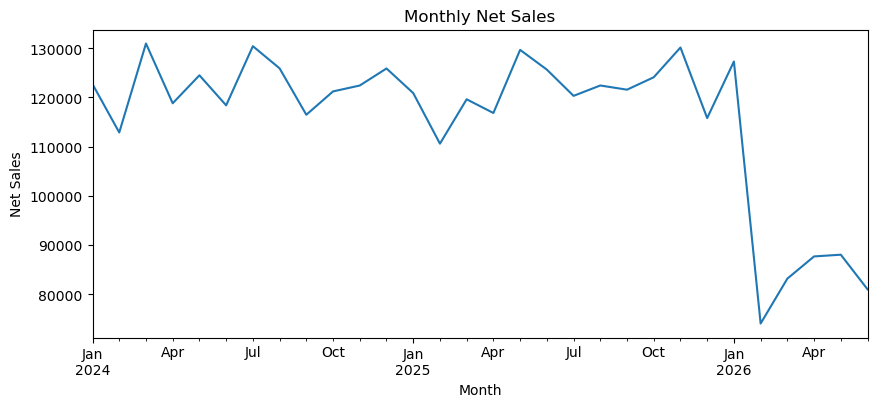

In [632]:
monthly_sales.plot(
    kind="line",
    figsize=(10, 4),
    title="Monthly Net Sales",
    xlabel="Month",
    ylabel="Net Sales"
)

As we can see from chart that the monthly sales have dropped in between January and February 2026 and still are not going above the 90000 mark. This can help us to determine the next strategies and find out what we exactly did in January 2026 that has caused this sudden drop.

In [634]:
monthly_sales.idxmax()

Period('2024-03', 'M')

In [635]:
monthly_sales.max()

130948.8

We can get the month that has highest monthly sales. .idxmax() will return the months that March 2024 and .max() function will return  the max entry which is 130948.8 so we know the company had monthly sale of 130948.9 in March 2024 which was highest monthly sale of the company.

In [637]:
monthly_sales.idxmin()

Period('2026-02', 'M')

In [638]:
monthly_sales.min()

74090.55

We also have got the month that has the lowest monthly sales which is February 2026 with the monthly sales of 74090.55

### Question 2: Which Product Category is Gererating the Most Revenue?

This is useful because it can show the business which product categories contribute most to sales, helping management decide where to focus inventory, marketing, and future product selection.

In [662]:
category_sales = completed_orders.groupby('Category')['NetSale'].sum()
category_sales

Category
Accessories     558201.80
Electronics    1758286.25
Gaming          200004.95
Home Office     450143.00
Stationery       66234.25
Wearables       436753.70
Name: NetSale, dtype: float64

Lets see this in the chart as well for better understanding.

<Axes: title={'center': 'Categorical Net Sales'}, xlabel='Category', ylabel='Net Sales'>

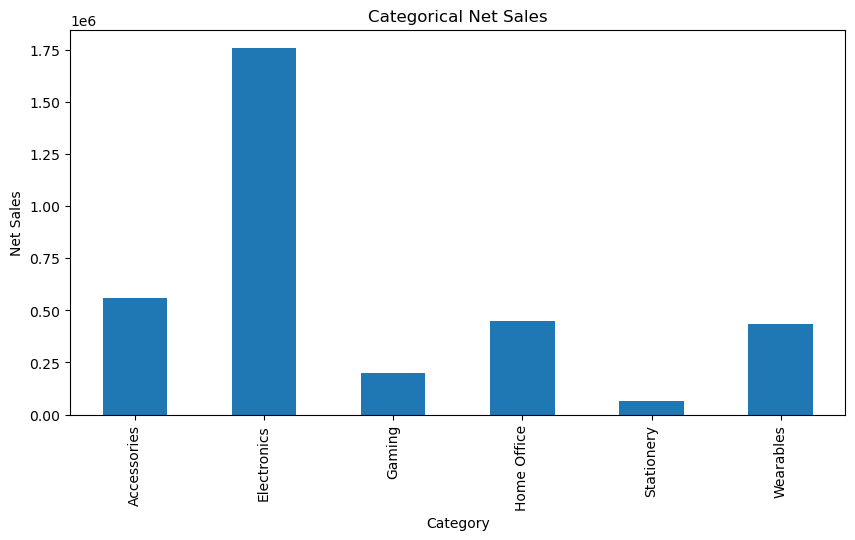

In [665]:
category_sales.plot(
    kind= 'bar',
    figsize= (10, 5),
    title= 'Categorical Net Sales',
    xlabel = 'Category',
    ylabel= 'Net Sales'
)

Electronic category has the highest number of sales while Stationary category has the lowest number of sales.

After finding the most selling category, we can find the most selling individual product to how much is a single product contributing to the total monthly sales.

In [669]:
product_sales = completed_orders.groupby('ProductName')['NetSale'].sum()
product_sales

ProductName
Backpack               172201.45
Bluetooth Speaker      214106.05
Desk Lamp              117937.05
Fitness Band           174281.55
Gaming Controller      200004.95
HDMI Cable              76237.55
Headphones             339119.40
Laptop Stand           111585.45
Mechanical Keyboard    225036.85
Microphone             233726.45
Monitor                 22353.05
Notebook                66234.25
Office Chair           332205.95
Phone Case             123982.90
Power Bank             181437.50
Smart Watch            262472.15
Tablet                 289852.05
USB-C Cable             74194.45
Webcam                 151264.90
Wireless Mouse         101390.00
Name: NetSale, dtype: float64

Lets view it in chart for better visibility and understanding.

<Axes: xlabel='Product Name', ylabel='Net Sales'>

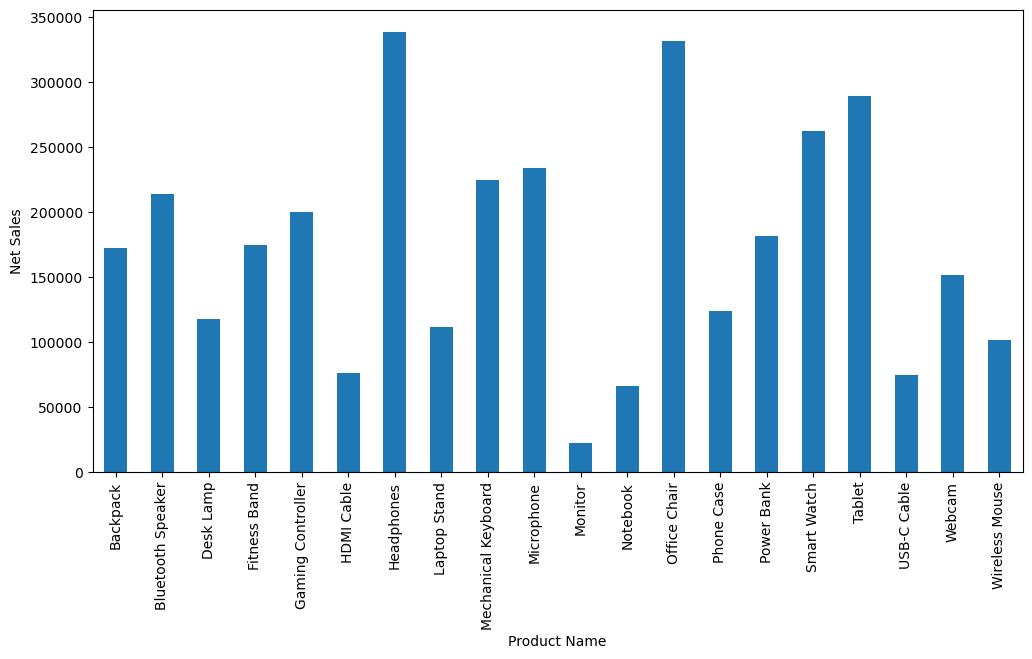

In [672]:
product_sales.plot(
    kind= 'bar',
    figsize= (12,6),
    label= 'Net Sales of each Product Available',
    xlabel = 'Product Name',
    ylabel= 'Net Sales'
)

Headphone is most selling product and at 2nd number is Office Chair and on the other hand Monitor has the lowest sales among other products. Now, company managent has clear data that product they need to work on and what products are doing well. 

### Question 3: How does the discount level relate to NetSales?

This is very important question because if discount is increasing the netsales then giving discounts is good for sales but if discount is not affecting the netsales then discount is hurting the netsales. Lets see first what discount values we have in our dataset.

In [677]:
completed_orders['Discount'].value_counts().sort_index()

Discount
0.00    16157
0.05    10006
0.10     9114
0.15     5503
0.20     3300
0.30     1793
Name: count, dtype: int64

In [679]:
discount_sales = completed_orders.groupby('Discount')['NetSale'].agg(['count', 'mean'])
discount_sales

,count,mean
Discount,,
0.00,16157,74.528316
0.05,10006,75.550040
0.10,9114,76.422383
0.15,5503,75.729702
0.20,3300,76.730000
0.30,1793,79.784216


Higher discount is generally associated with the slightly higher net sales as 30% discount has highest net sales but if we look at the number of completed orders we can establish that the company has 16157 orders without giving any discount and it has only 1793 orders with the highest dicount. So, the highest discount is not directly related to highest net sales and more number of orders. 

### Question 4: Which Category has the highest Return and Cancellation Rate?

Now, we can the use of dividing the original dataset into different datasets becuase it helps in writing the clean and understandable code. From return_orders and cancelled orders datasets we can derive the information what product categories have more return and cancellation rate than others.

In [684]:
returned_by_category = returned_orders['Category'].value_counts()
returned_by_category

Category
Accessories    571
Electronics    525
Stationery     199
Home Office     93
Wearables       86
Gaming          56
Name: count, dtype: int64

In [686]:
cancelled_by_category = cancelled_orders['Category'].value_counts()
cancelled_by_category

Category
Accessories    926
Electronics    899
Stationery     270
Home Office    145
Wearables      142
Gaming          81
Name: count, dtype: int64

From the above results, we can easily see that Accessories, Electronics and Stationary are top 3 categories with highes number of order returns and cancelled orders.  

### Question 5: Which products are purchased most frequently?

We have already seen which product is generating most net sales but we can look which product has most number of orders as a product can have high price and lower number of order that can contribute to high net sales.

In [691]:
sell_frequency = completed_orders['ProductName'].value_counts()
sell_frequency

ProductName
Notebook               5018
Phone Case             4637
USB-C Cable            4355
HDMI Cable             3647
Wireless Mouse         2979
Power Bank             2785
Headphones             2408
Backpack               2149
Laptop Stand           2148
Bluetooth Speaker      1978
Mechanical Keyboard    1977
Desk Lamp              1957
Fitness Band           1703
Webcam                 1679
Gaming Controller      1547
Microphone             1448
Smart Watch            1159
Office Chair            973
Monitor                 726
Tablet                  600
Name: count, dtype: int64

Lets see this in a chart.

<Axes: title={'center': 'Number of Sold Units of each Product'}, xlabel='ProductName', ylabel='Units Counts'>

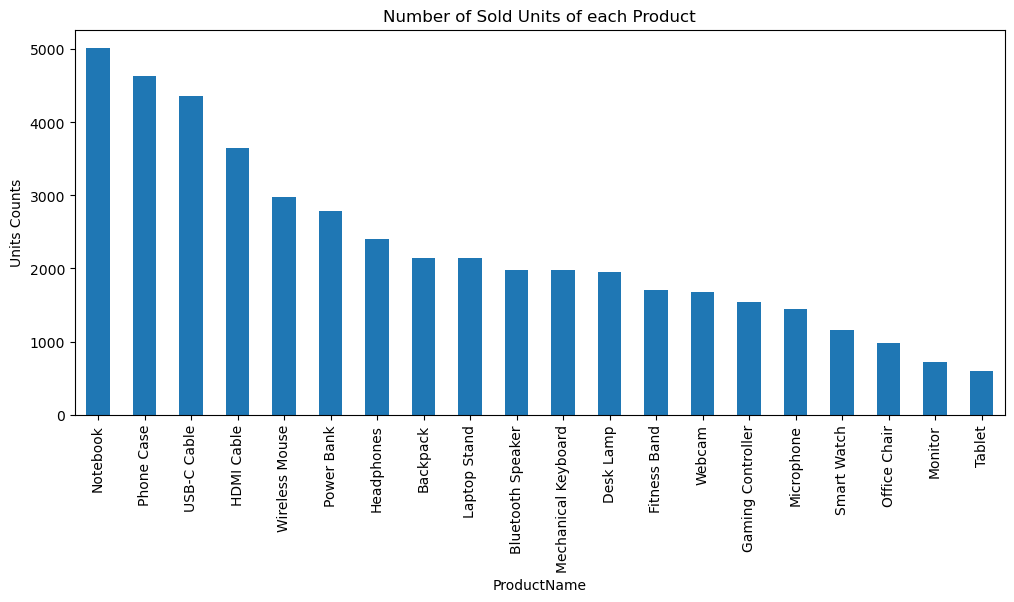

In [694]:
sell_frequency.plot(
    kind= 'bar',
    figsize= (12,5),
    title= 'Number of Sold Units of each Product',
    xlabel= 'ProductName',
    ylabel= 'Units Counts'
)

As this chart shows clearly even most net sales are being generated by Headphones and Office Chairs but most number of units sold are of Notebooks. This is very important for management to handle the inventory because they need more number of notebooks in inventory than Headphone despite the highes net sales.

### Question 6: Are there any Seasonal Patterns across Months or Quarters?

This is a valuable business question because identifying recurring periods of stronger or weaker sales can help with inventory planning, marketing campaigns, staffing, and budgeting.
Since we already created the Quarter column, we'll start with quarterly performance rather than repeating the monthly analysis.

In [699]:
quarterly_sales = completed_orders.groupby('Quarter')['NetSale'].mean()
quarterly_sales

Quarter
2024Q1    76.518737
2024Q2    75.513278
2024Q3    76.660189
2024Q4    75.614498
2025Q1    73.075588
2025Q2    75.167047
2025Q3    74.457940
2025Q4    76.171902
2026Q1    76.381897
2026Q2    77.588837
Freq: Q-DEC, Name: NetSale, dtype: float64

In [701]:
quarterly_size = completed_orders.groupby('Quarter').size()
quarterly_size

Quarter
2024Q1    4790
2024Q2    4790
2024Q3    4863
2024Q4    4887
2025Q1    4805
2025Q2    4951
2025Q3    4893
2025Q4    4858
2026Q1    3726
2026Q2    3310
Freq: Q-DEC, dtype: int64

We have concluded from these findings that on Quarterly basis average netsales and number of orders does not have much fluctuation. Only the start of 2026 have dropped in number of orders. 

We will do the same for monthly basis as we have there has not been a lot of seasonal pattern on basis of quarters of the year. 

In [705]:
monthly_sales_pattern = completed_orders.groupby('Month')['NetSale'].sum()
monthly_sales_pattern

Month
2024-01    122693.10
2024-02    112882.85
2024-03    130948.80
2024-04    118815.70
2024-05    124496.95
2024-06    118395.95
2024-07    130408.30
2024-08    125904.90
2024-09    116485.30
2024-10    121223.25
2024-11    122421.95
2024-12    125882.85
2025-01    120887.45
2025-02    110616.30
2025-03    119624.45
2025-04    116840.85
2025-05    129659.20
2025-06    125652.00
2025-07    120320.70
2025-08    122426.15
2025-09    121575.85
2025-10    124096.30
2025-11    130138.60
2025-12    115808.20
2026-01    127298.15
2026-02     74090.55
2026-03     83210.25
2026-04     87716.35
2026-05     88065.15
2026-06     81037.55
Freq: M, Name: NetSale, dtype: float64

The findings shows that the sales go down slightly in the month of February

In [708]:
monthly_size_pattern = completed_orders.groupby('Month').size()
monthly_size_pattern

Month
2024-01    1632
2024-02    1466
2024-03    1692
2024-04    1567
2024-05    1626
2024-06    1597
2024-07    1645
2024-08    1685
2024-09    1533
2024-10    1613
2024-11    1559
2024-12    1715
2025-01    1646
2025-02    1460
2025-03    1699
2025-04    1622
2025-05    1649
2025-06    1680
2025-07    1638
2025-08    1648
2025-09    1607
2025-10    1651
2025-11    1670
2025-12    1537
2026-01    1609
2026-02     996
2026-03    1121
2026-04    1090
2026-05    1160
2026-06    1060
Freq: M, dtype: int64

And the findings on size data also shows that the number of orders drop down slightly in the month of February compared to other months. 

### Question 7: What does the recent sales trend suggest about near-term future performance?

Since our latest monthly data is June 2026, we can use a 3-month moving average to estimate the near-term sales level. Moving averages are useful for smoothing short-term fluctuations and identifying the underlying recent trend.

In [713]:
monthly_sales = completed_orders.groupby("Month")["NetSale"].sum()

recent_moving_average = monthly_sales.rolling(3).mean().tail(6).round(2)

recent_moving_average

Month
2026-01    124414.98
2026-02    105732.30
2026-03     94866.32
2026-04     81672.38
2026-05     86330.58
2026-06     85606.35
Freq: M, Name: NetSale, dtype: float64

The smoothed monthly NetSales declined from £124,414.98 in January 2026 to £85,606.35 in June 2026, representing a reduction of approximately 31%. However, the moving average stabilised at around £85,000–£86,000 during May and June, suggesting that the decline may be slowing. Therefore, near-term performance is likely to remain below the levels observed in 2024–2025.

We can forecast July 2026 sales using last 3 months data.

In [716]:
july_forecast = monthly_sales.tail(3).mean().round(2)

july_forecast

85606.35

In [718]:
forecast_test = pd.DataFrame({
    "Actual": monthly_sales
})

forecast_test["Forecast_3M"] = monthly_sales.shift(1).rolling(3).mean()

forecast_test["Error"] = (
    forecast_test["Actual"] - forecast_test["Forecast_3M"]
)

forecast_test["Absolute_Error"] = forecast_test["Error"].abs()

forecast_test["Percentage_Error"] = (
    forecast_test["Absolute_Error"] / forecast_test["Actual"] * 100
).round(2)

forecast_test.tail(12)

,Actual,Forecast_3M,Error,Absolute_Error,Percentage_Error
Month,,,,,
2025-07,120320.70,124050.683333,-3729.983333,3729.983333,3.10
2025-08,122426.15,125210.633333,-2784.483333,2784.483333,2.27
2025-09,121575.85,122799.616667,-1223.766667,1223.766667,1.01
2025-10,124096.30,121440.900000,2655.400000,2655.400000,2.14
2025-11,130138.60,122699.433333,7439.166667,7439.166667,5.72
2025-12,115808.20,125270.250000,-9462.050000,9462.050000,8.17
2026-01,127298.15,123347.700000,3950.450000,3950.450000,3.10
2026-02,74090.55,124414.983333,-50324.433333,50324.433333,67.92
2026-03,83210.25,105732.300000,-22522.050000,22522.050000,27.07


From this data, we can see that the forecasts before February have very less percentage error but due to sudden drop in sales in February 2026 the percentage forecast error was increased but it got stabled in April 2026. According to this data, the monthly sales of July 2026 will be around 85606 with the average percentage error of 5%. 

### Question 8: How significant are cancellations and returns, and are they changing over time?

This question is important because it answers whether cancellations and returns are increasing or decreasing over time. This is very helpful for handling future cancellations and returns for the management.

In [723]:
monthly_status = pd.crosstab(
    merged_dataset["Month"],
    merged_dataset["Status"]
)

monthly_status["Cancellation_Rate"] = (
    monthly_status["Cancelled"] / monthly_status.sum(axis=1) * 100
).round(2)

monthly_status["Return_Rate"] = (
    monthly_status["Returned"] / monthly_status.sum(axis=1) * 100
).round(2)

monthly_status

Status,Cancelled,Completed,Returned,Cancellation_Rate,Return_Rate
Month,,,,,
2024-01,90,1632,46,5.09,2.59
2024-02,92,1466,50,5.72,3.10
2024-03,94,1692,51,5.12,2.77
2024-04,73,1567,57,4.30,3.35
2024-05,82,1626,58,4.64,3.28
2024-06,68,1597,47,3.97,2.74
2024-07,81,1645,33,4.60,1.87
2024-08,95,1685,55,5.18,2.99
2024-09,78,1533,48,4.70,2.89


Monthly cancellation rates are generally ranging between 4% and 6% and return rates between 2% and 4%. However, neither metric shows a consistent upward or downward trend over time. Return rates increased to 4.10% in March 2026 before declining to 2.75% in June, while the cancellation rate fluctuated and reached 5.78% in June. Therefore, cancellations and returns should be monitored as an operational concern, but the data does not provide evidence of a sustained deterioration in either metric.

## Final Discussion and Conclusion:

I have discussed the business context, data exploration, data preprocessing and most useful business question. It is time give final thoughts on strengths and limitation of data analysis, what are insights and implication of the result for the business and what are data driven recommendations as data science consultant to client company.

### Strengths and Limitations of Data Analysis:

The analysis has several strengths. 
First, data quality was systematically assessed and issues such as missing values, duplicate records and invalid or negative values were addressed before analysis. 
Second, the orders and products datasets were successfully integrated, enabling transaction-level analysis using product and category information. Third, multiple business perspectives were investigated, including sales trends, product performance, discounts, time patterns, forecasting and cancellations and returns. 

The analysis has several limitations. 
First, the whole process is based on historical transactions data and that is why it can not guarantee future business performance accurately. 
Second, the dataset contains only six months of data for 2026, limiting comparisons with complete previous years and making it difficult to determine whether the decline started in 2026 is temporary or persistent. 
Third, important explanatory variables such as marketing expenditure, inventory availability, competitor pricing and customer demographics are not available, limiting the ability to identify the causes of observed changes. The forecasting analysis also uses a relatively simple 3-month moving average, which does not explicitly account for seasonality or other external factors. 


### Insights:

The business performed relatively consistently during the years of 2024 and 2025 but experienced a broad decline in sales during 2026 especially in February 2026. This decline affected almost all of the categories and products rather than being isolated to one area, while the absence of a strong seasonal pattern suggests that the change may reflect a broader shift in business performance.

### Implications:

The findings have several business implications. 

First, the broad decline in sales during 2026 requires further investigation, as the dataset does not identify a single product or category responsible for the reduction. 

Second, strong-performing categories and products should remain a priority for inventory and promotional decisions. 

Finally, cancellations and returns should continue to be monitored because, although neither shows a sustained worsening trend.

### Data Driven Recommendations:

Based on the analysis and findings, four data-driven recommendations are proposed. 

First, management should investigate the underlying causes of the 2026 sales drop using additional information such as inventory, pricing, marketing and competitor data. 

Second, high-performing and relatively resilient products should be prioritised for inventory and promotional decisions. 

Third, discounts should be applied selectively and evaluated against profitability because higher discounts were associated with only modest increases in average NetSales. 

Finally, the business should establish regular monitoring of NetSales, cancellation rates, return rates and product performance to identify emerging changes and evaluate whether the recent decline stabilises.

### Conclusion:

This analysis provided a comprehensive assessment of e-commerce sales performance using transactions and product data. Sales remained relatively stable during 2024 and 2025 but declined substantially during 2026. Electronics remained the strongest revenue-generating category. The analysis found no strong recurring seasonal pattern on quarter of the year or monthly basis, while the forecasting analysis suggested that near-term sales may remain below historical levels despite recent signs of stabilisation. Cancellations and returns were meaningful operational measures but did not show a sustained deterioration. Overall, the findings indicate that the business should investigate the causes of the 2026 decline, prioritise stronger-performing products, use discounts selectively, and monitor key performance indicators regularly.

## References:


Kaggle  *E-commerce Sales Data Analysis and EDA*. Available at: https://www.kaggle.com/datasets/erfan4524/e-commerce-sales-data-analysis-and-eda/data (Accessed: 6 September 2026).

pandas development team  *pandas documentation*. Available at: https://pandas.pydata.org/docs/ (Accessed: 13 September 2026).

Python Software Foundation  *Python documentation*. Available at: https://docs.python.org/3/ (Accessed: 13 September 2026).